# Open-Meteo Event-Local Historical Weather API

Collect weather at each India-covered disaster event location and event date.

Fields:

- Temperature
- Rainfall
- Humidity
- Wind Speed

Output:

`datasets/weather_data.csv` with one row per `SourceEventID`.

In [1]:
from pathlib import Path
import time

import numpy as np
import pandas as pd
import rasterio
from rasterio.windows import Window
import requests
import matplotlib.pyplot as plt


current_dir = Path.cwd()
PROJECT_ROOT = current_dir.parent if current_dir.name == "notebooks" else current_dir
DATA_DIR = PROJECT_ROOT / "datasets"
#EARTHQUAKE_PATH = DATA_DIR / "earthquake_data.csv"
POPULATION_RASTER_PATH = DATA_DIR / "population_data.tif"


#WEATHER_PATH = DATA_DIR / "weather_data.csv" (for 18k rows diaster)
WEATHER_PATH = DATA_DIR / "weather_useful_events.csv"

#EVENT_FILE = (DATA_DIR /"combined_disasters.csv") (for 18k rows diaster)
EVENT_FILE = (DATA_DIR /"useful_disaster_events.csv")

ARCHIVE_URL = "https://archive-api.open-meteo.com/v1/archive"
REQUEST_PAUSE_SECONDS = 0.5
MAX_WEATHER_EVENTS = None  # Set to None after validating the workflow on a small batch.

print(f"Project root: {PROJECT_ROOT}")
print(f"Weather output: {WEATHER_PATH}")

Project root: C:\Users\aashi\PycharmProjects\AI-Based Disaster Response Management System for Resource Allocation and Relief Coordination
Weather output: C:\Users\aashi\PycharmProjects\AI-Based Disaster Response Management System for Resource Allocation and Relief Coordination\datasets\weather_useful_events.csv


In [2]:
def point_inside_bounds(latitude, longitude, bounds):
    return (
        bounds.left <= longitude <= bounds.right
        and bounds.bottom <= latitude <= bounds.top
    )


def point_inside_valid_population_pixel(dataset, latitude, longitude):
    if not point_inside_bounds(latitude, longitude, dataset.bounds):
        return False

    row, col = dataset.index(longitude, latitude)
    if row < 0 or col < 0 or row >= dataset.height or col >= dataset.width:
        return False

    value = float(dataset.read(1, window=Window(col, row, 1, 1))[0, 0])
    if dataset.nodata is not None and value == dataset.nodata:
        return False
    if value < 0 or np.isnan(value):
        return False

    return True


def build_archive_params(latitude, longitude, event_time):
    event_date = event_time.date().isoformat()
    return {
        "latitude": latitude,
        "longitude": longitude,
        "start_date": event_date,
        "end_date": event_date,
        "hourly": "temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m",
        "timezone": "UTC",
    }

In [3]:
if not EVENT_FILE.exists():
    raise FileNotFoundError(f"Missing disaster data: {EVENT_FILE}")

disaster_df = pd.read_csv(EVENT_FILE)
if "SourceEventID" not in disaster_df.columns:
    disaster_df = disaster_df.reset_index().rename(columns={"index": "SourceEventID"})

for column in ["Latitude", "Longitude", "Magnitude", "Depth"]:
    disaster_df[column] = pd.to_numeric(disaster_df[column], errors="coerce")

# Convert mixed USGS + GDACS time formats

disaster_df["EventTime"] = pd.to_datetime(
    disaster_df["Time"],
    errors="coerce"
)


missing_time = disaster_df["EventTime"].isna()


disaster_df.loc[
    missing_time,
    "EventTime"
] = pd.to_datetime(

    disaster_df.loc[
        missing_time,
        "Time"
    ],

    unit="ms",

    errors="coerce"

)
disaster_df = disaster_df.dropna(subset=["SourceEventID", "Latitude", "Longitude", "EventTime"]).copy()

# Use all combined disasters for weather collection

india_events = disaster_df.copy()


print(
    "Total disaster events:",
    len(disaster_df)
)


print(
    "Events selected for weather:",
    len(india_events)
)


india_events[
    [
        "SourceEventID",
        "Latitude",
        "Longitude",
        "EventTime"
    ]
].head()

Total disaster events: 2351
Events selected for weather: 2351


,SourceEventID,Latitude,Longitude,EventTime
0,18,27.5051,92.1524,2026-06-21 00:53:20.927
1,19,27.4598,92.0424,2026-06-21 00:52:54.610
2,22,24.3478,94.0847,2026-06-18 15:29:24.907
3,39,24.9682,93.0641,2026-06-11 15:40:35.593
4,46,32.3888,76.6062,2026-06-05 16:34:36.131


In [4]:
WEATHER_COLUMNS = [
    "SourceEventID",
    "Latitude",
    "Longitude",
    "EventTime",
    "WeatherTime",
    "Temperature",
    "Humidity",
    "Rainfall",
    "WindSpeed",
]


def load_existing_weather():
    if not WEATHER_PATH.exists():
        return pd.DataFrame(columns=WEATHER_COLUMNS)

    existing = pd.read_csv(WEATHER_PATH)
    if existing.empty or "SourceEventID" not in existing.columns:
        empty = pd.DataFrame(columns=WEATHER_COLUMNS)
        empty.to_csv(WEATHER_PATH, index=False)
        return empty

    existing = existing.drop_duplicates(subset=["SourceEventID"], keep="last")
    for column in WEATHER_COLUMNS:
        if column not in existing.columns:
            existing[column] = pd.NA
    existing = existing[WEATHER_COLUMNS]
    existing.to_csv(WEATHER_PATH, index=False)
    return existing


def append_weather_row(row):
    pd.DataFrame([row], columns=WEATHER_COLUMNS).to_csv(
        WEATHER_PATH,
        mode="a",
        header=not WEATHER_PATH.exists(),
        index=False,
    )

In [5]:
def fetch_weather_for_event(event):

    params = build_archive_params(
        event.Latitude,
        event.Longitude,
        event.EventTime
    )


    for attempt in range(5):

        try:

            response = requests.get(

                ARCHIVE_URL,

                params=params,

                timeout=30

            )


            if response.status_code == 429:

                print(
                    "API limit/rate reached. Waiting..."
                )


                time.sleep(120)


                continue


            response.raise_for_status()


            weather_json = response.json()


            break


        except Exception as error:


            print(

                f"Attempt {attempt+1} failed:",

                error

            )


            time.sleep(30)


    else:


        return {

            "SourceEventID": int(event.SourceEventID),

            "Latitude": float(event.Latitude),

            "Longitude": float(event.Longitude),

            "EventTime": event.EventTime,

            "WeatherTime": pd.NaT,

            "Temperature": np.nan,

            "Humidity": np.nan,

            "Rainfall": np.nan,

            "WindSpeed": np.nan,

        }



    hourly = weather_json["hourly"]


    hourly_df = pd.DataFrame(

        {

            "WeatherTime":

            pd.to_datetime(
                hourly["time"],
                errors="coerce"
            ),


            "Temperature":

            hourly["temperature_2m"],


            "Humidity":

            hourly["relative_humidity_2m"],


            "Rainfall":

            hourly["precipitation"],


            "WindSpeed":

            hourly["wind_speed_10m"],

        }

    ).dropna(
        subset=["WeatherTime"]
    )


    nearest_index = (

        hourly_df["WeatherTime"]

        -

        event.EventTime

    ).abs().idxmin()


    nearest = hourly_df.loc[

        nearest_index

    ]



    return {

        "SourceEventID":

        int(event.SourceEventID),


        "Latitude":

        float(event.Latitude),


        "Longitude":

        float(event.Longitude),


        "EventTime":

        event.EventTime,


        "WeatherTime":

        nearest["WeatherTime"],


        "Temperature":

        float(nearest["Temperature"]),


        "Humidity":

        float(nearest["Humidity"]),


        "Rainfall":

        float(nearest["Rainfall"]),


        "WindSpeed":

        float(nearest["WindSpeed"])

    }

In [6]:
existing_weather_df = load_existing_weather()
processed_event_ids = set(existing_weather_df["SourceEventID"].dropna().astype(int))

events_to_process = india_events.loc[
    ~india_events["SourceEventID"].astype(int).isin(processed_event_ids)
].copy()
if MAX_WEATHER_EVENTS is not None:
    events_to_process = events_to_process.head(MAX_WEATHER_EVENTS)

print(f"Already processed weather events: {len(processed_event_ids)}")
print(f"Processing weather for {len(events_to_process)} of {len(india_events)} India events")

new_rows = []
for event_number, event in enumerate(events_to_process.itertuples(index=False), start=1):
    try:
        print(f"[{event_number}/{len(events_to_process)}] Weather for SourceEventID {event.SourceEventID}")
        weather_row = fetch_weather_for_event(event)
        append_weather_row(weather_row)
        new_rows.append(weather_row)
        print(f"Checkpoint saved: {WEATHER_PATH}")
    except Exception as error:
        print(f"Weather query failed for SourceEventID {event.SourceEventID}: {error}")

    time.sleep(REQUEST_PAUSE_SECONDS)

weather_df = pd.concat(
    [existing_weather_df, pd.DataFrame(new_rows, columns=WEATHER_COLUMNS)],
    ignore_index=True,
).drop_duplicates(subset=["SourceEventID"], keep="last")
weather_df = weather_df[WEATHER_COLUMNS]
weather_df.head()

Already processed weather events: 2351
Processing weather for 0 of 2351 India events


C:\Users\aashi\AppData\Local\Temp\ipykernel_3764\3426641393.py:26: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  weather_df = pd.concat(


,SourceEventID,Latitude,Longitude,EventTime,WeatherTime,Temperature,Humidity,Rainfall,WindSpeed
0,18,27.5051,92.1524,2026-06-21 00:53:20.927,2026-06-21 01:00:00,6.2,84.0,0.0,4.3
1,19,27.4598,92.0424,2026-06-21 00:52:54.610,2026-06-21 01:00:00,10.6,92.0,0.0,2.1
2,22,24.3478,94.0847,2026-06-18 15:29:24.907,2026-06-18 15:00:00,20.7,92.0,0.0,6.7
3,39,24.9682,93.0641,2026-06-11 15:40:35.593,2026-06-11 16:00:00,27.3,87.0,0.0,2.4
4,46,32.3888,76.6062,2026-06-05 16:34:36.131,2026-06-05 17:00:00,-3.7,98.0,0.0,3.1


In [7]:
weather_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2351 entries, 0 to 2350
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   SourceEventID  2351 non-null   object 
 1   Latitude       2351 non-null   float64
 2   Longitude      2351 non-null   float64
 3   EventTime      2351 non-null   object 
 4   WeatherTime    2351 non-null   object 
 5   Temperature    2351 non-null   float64
 6   Humidity       2351 non-null   float64
 7   Rainfall       2351 non-null   float64
 8   WindSpeed      2351 non-null   float64
dtypes: float64(6), object(3)
memory usage: 165.4+ KB


In [8]:
weather_df.isnull().sum()

SourceEventID    0
Latitude         0
Longitude        0
EventTime        0
WeatherTime      0
Temperature      0
Humidity         0
Rainfall         0
WindSpeed        0
dtype: int64

In [9]:
weather_df.describe()

,Latitude,Longitude,Temperature,Humidity,Rainfall,WindSpeed
count,2351.000000,2351.000000,2351.000000,2351.000000,2351.000000,2351.000000
mean,22.712318,86.456094,18.419779,72.307954,0.188473,9.409230
std,8.637363,8.858540,12.410518,21.332575,0.664491,8.087889
min,6.757000,68.963000,-33.600000,5.000000,0.000000,0.000000
25%,13.492500,76.761500,12.800000,63.000000,0.000000,3.600000
50%,24.525800,92.448500,23.500000,78.000000,0.000000,6.400000
75%,29.093400,93.233200,27.000000,87.000000,0.100000,13.100000
max,35.479000,97.352100,42.000000,100.000000,12.200000,50.700000


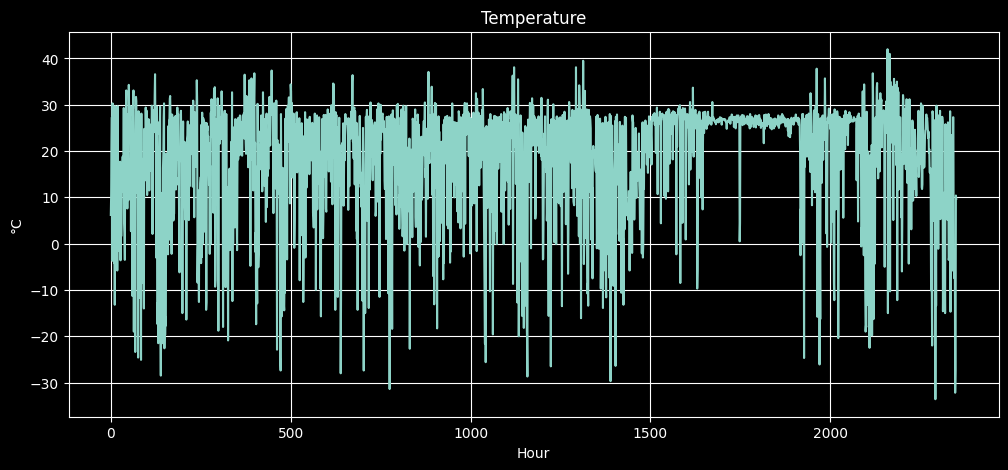

In [10]:
plt.figure(figsize=(12,5))

plt.plot(weather_df["Temperature"])

plt.title("Temperature")

plt.xlabel("Hour")

plt.ylabel("°C")

plt.grid()

plt.show()

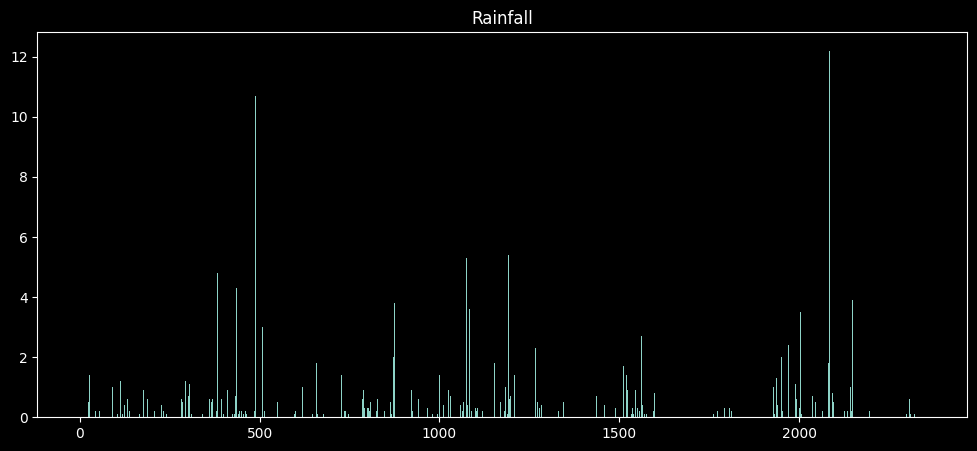

In [11]:
plt.figure(figsize=(12,5))

plt.bar(

    weather_df.index,

    weather_df["Rainfall"]

)

plt.title("Rainfall")

plt.show()

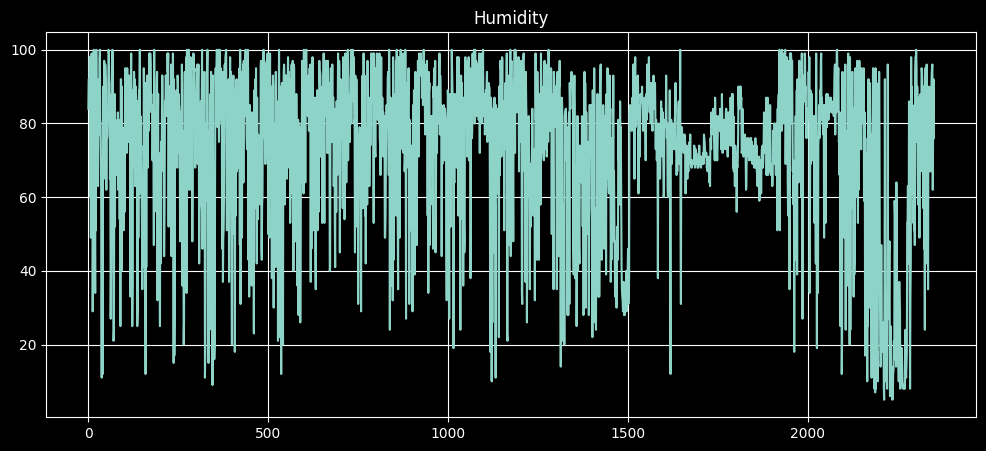

In [12]:
plt.figure(figsize=(12,5))

plt.plot(

    weather_df["Humidity"]

)

plt.title("Humidity")

plt.grid()

plt.show()

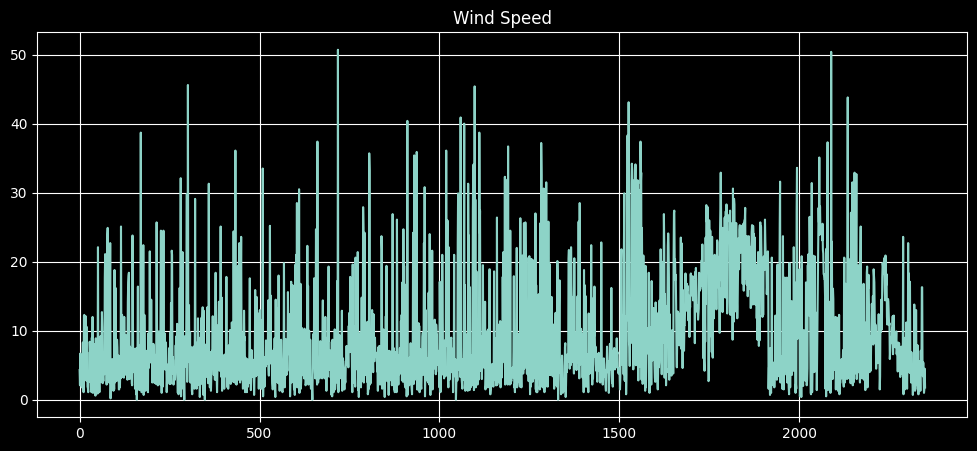

In [13]:
plt.figure(figsize=(12,5))

plt.plot(

    weather_df["WindSpeed"]

)

plt.title("Wind Speed")

plt.grid()

plt.show()

In [14]:
weather_df.to_csv(WEATHER_PATH, index=False)

print(f"Weather dataset saved: {WEATHER_PATH}")
print(f"Rows saved: {len(weather_df)}")

Weather dataset saved: C:\Users\aashi\PycharmProjects\AI-Based Disaster Response Management System for Resource Allocation and Relief Coordination\datasets\weather_useful_events.csv
Rows saved: 2351


In [15]:
sorted(path.name for path in DATA_DIR.iterdir())

['combined_disasters.csv',
 'earthquake_data.csv',
 'event_infrastructure_summary.csv',
 'final_disaster_dataset.csv',
 'final_disaster_dataset_engineered.csv',
 'final_disaster_dataset_with_infrastructure.csv',
 'gdacs_data.csv',
 'india-latest.osm.pbf',
 'india_infrastructure.parquet',
 'osm_checkpoints',
 'osm_regions',
 'population_clean.npy',
 'population_data.tif',
 'population_metadata.json',
 'population_selected_metadata.json',
 'shapefiles',
 'useful_disaster_events.csv',
 'weather_data.csv',
 'weather_useful_events.csv']

In [16]:
weather_df.head(10)

,SourceEventID,Latitude,Longitude,EventTime,WeatherTime,Temperature,Humidity,Rainfall,WindSpeed
0,18,27.5051,92.1524,2026-06-21 00:53:20.927,2026-06-21 01:00:00,6.2,84.0,0.0,4.3
1,19,27.4598,92.0424,2026-06-21 00:52:54.610,2026-06-21 01:00:00,10.6,92.0,0.0,2.1
2,22,24.3478,94.0847,2026-06-18 15:29:24.907,2026-06-18 15:00:00,20.7,92.0,0.0,6.7
3,39,24.9682,93.0641,2026-06-11 15:40:35.593,2026-06-11 16:00:00,27.3,87.0,0.0,2.4
4,46,32.3888,76.6062,2026-06-05 16:34:36.131,2026-06-05 17:00:00,-3.7,98.0,0.0,3.1
5,74,26.0613,89.8969,2026-05-09 09:10:05.675,2026-05-09 09:00:00,30.3,60.0,0.0,6.4
6,76,28.8263,95.9696,2026-05-06 15:17:33.655,2026-05-06 15:00:00,14.4,86.0,0.3,1.8
7,93,23.8301,94.2031,2026-04-21 14:24:37.187,2026-04-21 14:00:00,29.3,49.0,0.0,6.5
8,95,24.6319,94.6985,2026-04-21 00:29:35.307,2026-04-21,23.5,90.0,0.0,5.0
9,106,27.3137,92.0096,2026-04-14 21:04:50.603,2026-04-14 21:00:00,-4.2,99.0,0.1,8.3
